In [13]:
!pip install matplotlib statsmodels scikit-learn pandas numpy



Defaulting to user installation because normal site-packages is not writeable



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
import numpy as np
import pandas as pd
from pandas import Series
import matplotlib.pyplot as plt
from statsmodels.stats.stattools import jarque_bera

import statsmodels.api as sm
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.arima.model import ARIMA

from sklearn.svm import SVR
from sklearn.preprocessing import MinMaxScaler
import warnings
warnings.filterwarnings("ignore")


In [ ]:

import os
class_file = r'C:\Users\rafaelmg\Downloads\algorithms-ML\main\dataset\yahoo_stock.csv'

df = pd.read_csv(class_file, index_col=False, sep=',')
df.drop('High', inplace=True, axis=1)
df.drop('Low', inplace=True, axis=1)
df.drop('Open', inplace=True, axis=1)
df.drop('Volume', inplace=True, axis=1)
df.drop('Adj Close', inplace=True, axis=1)

df.index = pd.to_datetime(df.Date, format="%Y-%m-%d")
df.drop("Date", inplace=True, axis=1)

serie_original = df.iloc[:,0]
serie_size = len(serie_original)
intervalo = 15


In [16]:
def previsao_ets(desp_serie, intervalo, parametros):
    error = parametros[0]
    trend = parametros[1]
    seasonal = parametros[2]
    initialization = parametros[3]
    seasonal_periods = parametros[4]

    arr_real = []
    inter_real = []

    for i in range(intervalo):
        max_size = max(desp_serie.index)
        arr_real.append(desp_serie[max_size])
        inter_real.append(max_size)
        desp_serie = desp_serie.drop(max_size)

    model = ETSModel(desp_serie, error=error, trend=trend, seasonal=seasonal,
                     initialization_method=initialization,
                     seasonal_periods=seasonal_periods)
    model_fit = model.fit(disp=0)

    start = len(desp_serie)
    end = len(desp_serie) + intervalo - 1
    previsto = model_fit.predict(start=start, end=end)

    serie_real = Series(arr_real, inter_real).iloc[::-1]
    previsto = Series(np.asarray(previsto), index=serie_real.index)

    erro = []
    for i in range(len(previsto)):
        parc_erro = (previsto.iloc[i] - serie_real.iloc[i]) / serie_real.iloc[i]
        erro.append(abs(parc_erro))

    return abs(np.mean(erro)), previsto, model_fit

In [17]:
def previsao_arima(desp_serie, intervalo, parametros):
    p, d, q = parametros

    arr_real = []
    inter_real = []
    serie_treino = desp_serie.copy()

    for i in range(intervalo):
        max_size = max(serie_treino.index)
        arr_real.append(serie_treino[max_size])
        inter_real.append(max_size)
        serie_treino = serie_treino.drop(max_size)

    try:
        model = ARIMA(serie_treino, order=(p, d, q))
        model_fit = model.fit()
    except Exception:
        return 99, None, None

    start = len(serie_treino)
    end = len(serie_treino) + intervalo - 1
    previsto = model_fit.predict(start=start, end=end)

    serie_real = Series(arr_real, inter_real).iloc[::-1]
    previsto = Series(np.asarray(previsto), index=serie_real.index)

    erro = []
    for i in range(len(previsto)):
        parc_erro = (previsto.iloc[i] - serie_real.iloc[i]) / serie_real.iloc[i]
        erro.append(abs(parc_erro))

    return abs(np.mean(erro)), previsto, model_fit

In [18]:
def criar_dataset_supervisionado(serie, lag):
    X, y = [], []
    valores = serie.values
    for i in range(lag, len(valores)):
        X.append(valores[i - lag:i])
        y.append(valores[i])
    return np.array(X), np.array(y)


def previsao_svr(desp_serie, intervalo, parametros):
    kernel, C, epsilon, lag = parametros

    arr_real, inter_real = [], []
    serie_treino = desp_serie.copy().astype(float)

    for _ in range(intervalo):
        max_size = max(serie_treino.index)
        arr_real.append(serie_treino[max_size])
        inter_real.append(max_size)
        serie_treino = serie_treino.drop(max_size)

    X, y = criar_dataset_supervisionado(serie_treino, lag)
    if len(X) < 10:
        return 99, None, None

    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()
    X_scaled = scaler_X.fit_transform(X)
    y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()

    model = SVR(kernel=kernel, C=C, epsilon=epsilon)
    model.fit(X_scaled, y_scaled)

    janela = list(serie_treino.values[-lag:])
    previsoes = []
    for _ in range(intervalo):
        x_next = scaler_X.transform(np.array(janela[-lag:]).reshape(1, -1))
        y_pred = model.predict(x_next)[0]
        y_pred_real = scaler_y.inverse_transform([[y_pred]])[0][0]
        previsoes.append(y_pred_real)
        janela.append(y_pred_real)

    serie_real = Series(arr_real, inter_real).iloc[::-1]
    previsto = Series(previsoes, index=serie_real.index)

    erro = [abs((previsto.iloc[i] - serie_real.iloc[i]) / serie_real.iloc[i])
            for i in range(len(previsto))]

    return abs(np.mean(erro)), previsto, model



============ Melhores Parametros ============
ETS : ['add', 'mul', 'mul', 'heuristic', 18] -> MAPE: 0.89 %
ARIMA: [2, 1, 2] -> MAPE: 1.11 %
SVR : ['linear', 10, 0.01, 5] -> MAPE: 0.67 %


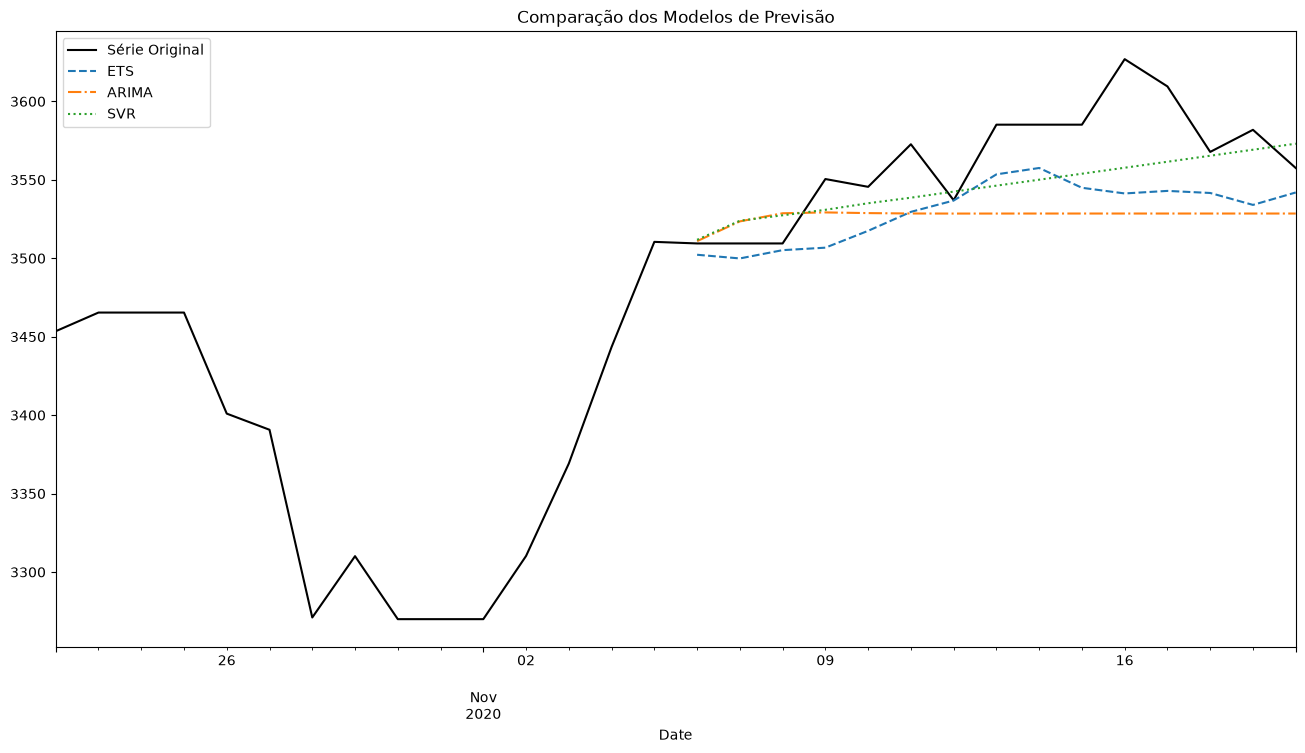

In [ ]:
v_erro = ['add', 'mul']
v_trend = ['add', 'mul']
v_seasonal = ['add', 'mul']
v_init = ['estimated', 'heuristic']
v_periodo = [18]

best_ets_erro = 99
best_ets_para, best_ets_prev, modelo_ets = [], [], ''

for erro in v_erro:
    for trend in v_trend:
        for seasonal in v_seasonal:
            for init in v_init:
                for period in v_periodo:
                    parametros = [erro, trend, seasonal, init, period]
                    vlerro, serie_prevista, modelo_tmp = previsao_ets(
                        serie_original, intervalo, parametros)
                    if vlerro < best_ets_erro and not np.isnan(vlerro):
                        best_ets_erro = vlerro
                        best_ets_para = parametros
                        best_ets_prev = serie_prevista
                        modelo_ets = modelo_tmp


best_arima_erro = 99
best_arima_para, best_arima_prev, modelo_arima = [], [], ''

for p in [0, 1, 2]:
    for d in [0, 1]:
        for q in [0, 1, 2]:
            parametros = [p, d, q]
            vlerro, serie_prevista, modelo_tmp = previsao_arima(
                serie_original, intervalo, parametros)
            if vlerro < best_arima_erro and not np.isnan(vlerro):
                best_arima_erro = vlerro
                best_arima_para = parametros
                best_arima_prev = serie_prevista
                modelo_arima = modelo_tmp


best_svr_erro = 99
best_svr_para, best_svr_prev, modelo_svr = [], [], ''

for kernel in ['rbf', 'linear']:
    for C in [1, 10, 100]:
        for epsilon in [0.01, 0.1]:
            for lag in [5, 10, 20]:
                parametros = [kernel, C, epsilon, lag]
                vlerro, serie_prevista, modelo_tmp = previsao_svr(
                    serie_original, intervalo, parametros)
                if vlerro < best_svr_erro and not np.isnan(vlerro):
                    best_svr_erro = vlerro
                    best_svr_para = parametros
                    best_svr_prev = serie_prevista
                    modelo_svr = modelo_tmp

print('Melhores Parametros')
print('ETS :', best_ets_para, '-> MAPE:', round(best_ets_erro*100, 2), '%')
print('ARIMA:', best_arima_para, '-> MAPE:', round(best_arima_erro*100, 2), '%')
print('SVR :', best_svr_para, '-> MAPE:', round(best_svr_erro*100, 2), '%')

for nome, prev in [('ETS', best_ets_prev),
                   ('ARIMA', best_arima_prev),
                   ('SVR', best_svr_prev)]:
    if prev is None or len(prev) == 0:
        print(f'{nome} não encontrou modelo válido!')



plt.figure(figsize=(16, 8))
serie_original[serie_size-2*intervalo:serie_size].plot(label='Série Original', color='black')

if len(best_ets_prev) > 0:
    best_ets_prev.plot(label='ETS', linestyle='--')
if len(best_arima_prev) > 0:
    best_arima_prev.plot(label='ARIMA', linestyle='-.')
if len(best_svr_prev) > 0:
    best_svr_prev.plot(label='SVR', linestyle=':')

plt.title('Comparação dos Modelos')
plt.legend()
plt.show()


